# House prices - guided exercise

**Goal : predict the price of a house in the US from its characteristics.**

You are given a file `house_prices.csv` containing 21 613 houses sold near Seattle.
Each row is one sale, with the surface, the number of rooms, the year of construction, etc.

By the end of this notebook you will have built a program that, given a new house, answers
*"this one should sell for about 450 000 $"*.

---

## How to use this notebook

+ A notebook is a list of **cells**. A grey cell contains code, a white one contains text.
+ To run a cell : click on it, then press **Shift + Enter**.
+ Cells must be run **from top to bottom**. If you skip one, the next ones will fail because a
  variable will not exist yet.
+ If everything breaks : menu *Kernel* -> *Restart & Run All* to start again from zero.

The notebook alternates between two kinds of cells :

| | |
|---|---|
| **EXAMPLE** | code already written, just run it and read it |
| **YOUR TURN** | a cell with `# TODO`, you have to complete it |

Every *YOUR TURN* is followed by a hint. Try before reading it.

## The 5 steps of the project

This is the plan of the whole notebook. It is also the plan of almost every machine learning project.

| Step | What we do | Why |
|---|---|---|
| 1. Explore | look at the data, count, plot | you cannot predict what you do not understand |
| 2. Clean | turn text into numbers, remove useless columns | a model only eats numbers |
| 3. Split | keep 20% of the houses aside | to check the model on houses it has never seen |
| 4. Normalize | put every column on the same scale | so that no column crushes the others |
| 5. Train & compare | try several models, measure the error | to pick the best one |

---
# Cheat sheet

Come back to this section whenever you are stuck. You do **not** have to learn it by heart.

## pandas : working with a table

A `DataFrame` is a table, like an Excel sheet. `df` is the usual name for it.

```python
df = pd.read_csv("file.csv")   # read a csv file into a table
df.head()                      # show the 5 first rows
df.head(20)                    # show the 20 first rows
df.shape                       # (number of rows, number of columns)
df.columns                     # the list of column names
df.info()                      # the type of each column + missing values
df.describe()                  # min, max, mean... of each numeric column

df["price"]                    # ONE column (the result is a Series)
df[["price", "bedrooms"]]      # SEVERAL columns (note the double brackets)
df["price"].mean()             # average of a column
df["price"].max()              # maximum
df["bedrooms"].value_counts()  # how many houses have 1, 2, 3... bedrooms
df["condition"].unique()       # the different values found in a column

df["price"] > 500000           # a column of True/False
df[df["price"] > 500000]       # keep only the rows where it is True

df.isna().sum()                # count the missing values, column by column
df.drop(columns=["id"])        # return the table WITHOUT the column id
df.corr(numeric_only=True)     # correlation between every pair of columns
```

**Careful :** `df.drop(...)` does not modify `df`, it returns a new table.
You have to write `df = df.drop(...)` to keep the result.

Documentation :
[10 minutes to pandas](https://pandas.pydata.org/docs/user_guide/10min.html) -
[read_csv](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html) -
[describe](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html)

## matplotlib : drawing a plot

Always the same 3 steps : **create** the figure, **draw**, **show**.

```python
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))        # 1. a figure 8 inches wide, 5 high
plt.scatter(x, y)                 # 2. draw
plt.xlabel("surface (sqft)")      #    always label your axes
plt.ylabel("price ($)")
plt.title("Price against surface")
plt.show()                        # 3. display it
```

The 4 plots you need in this notebook :

```python
plt.hist(df["price"], bins=50)      # distribution of ONE variable
plt.scatter(df["sqft_living"], df["price"], s=2)   # link between TWO variables
plt.bar(names, values)              # compare categories (vertical bars)
plt.barh(names, values)             # same, horizontal (better for long names)
```

Useful options : `s=2` the size of the dots, `alpha=0.3` transparency (essential when
thousands of dots overlap), `color="red"`, `label="..."` combined with `plt.legend()`.

Documentation :
[pyplot tutorial](https://matplotlib.org/stable/tutorials/pyplot.html) -
[scatter](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html) -
[hist](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html)

---
# Step 0 - Load everything

`import` makes a toolbox available. `as pd` is a nickname, so that we can write `pd` instead of
`pandas` every time.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries loaded")

Libraries loaded


In [2]:
df = pd.read_csv("house_prices.csv")   # Read the file into a table

print("The table has", df.shape[0], "rows and", df.shape[1], "columns")
df.head()   # The last line of a cell is displayed automatically

The table has 21613 rows and 21 columns


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,N,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,N,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,N,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,N,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,N,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


---
# Step 1 - Explore the data

Before writing any model, you must be able to answer : *what is in this file ?*

### EXAMPLE

`describe()` gives you the min, the max and the mean of every numeric column.
Read the `price` line carefully.

In [3]:
df.describe()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,view,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,4.580302e+09,5.400881e+05,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,0.234303,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,2.876566e+09,3.671272e+05,0.930062,0.770163,918.440897,4.142051e+04,0.539989,0.766318,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,4.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


### YOUR TURN

Answer these 3 questions by writing code in the cell below :

1. What is the **average** price ?
2. What is the price of the **most expensive** house ?
3. How many houses have **more than 5 bedrooms** ?

In [4]:
# TODO : question 1
print("Average price :", ...)

# TODO : question 2
print("Most expensive :", ...)

# TODO : question 3
print("Houses with more than 5 bedrooms :", ...)

Average price : Ellipsis
Most expensive : Ellipsis
Houses with more than 5 bedrooms : Ellipsis


<details>
<summary><b>Hint (click to open)</b></summary>

1. `df["price"].mean()`
2. `df["price"].max()`
3. `df[df["bedrooms"] > 5]` gives the table of these houses. `len(...)` gives its number of rows.

</details>

### EXAMPLE - missing values

A missing value (`NaN`, *Not a Number*) is an empty cell. Most models refuse to work with them.
`isna()` turns the table into True/False, and `sum()` counts the `True`.

In [5]:
df.isna().sum()   # Number of missing values per column

id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

**Good news : everything is at 0, there is no missing value in this file.**

That is rare. If there had been some, the two classic solutions would have been :

```python
df = df.dropna()                                  # delete the incomplete rows
df["bedrooms"] = df["bedrooms"].fillna(df["bedrooms"].mean())   # or fill them
```

But be careful, a `0` is not always a missing value. Here `sqft_basement = 0` really means
*this house has no basement*. Replacing it by the mean would be a mistake.

### EXAMPLE - the distribution of the prices

A histogram cuts the prices into 50 slices and counts how many houses fall into each slice.

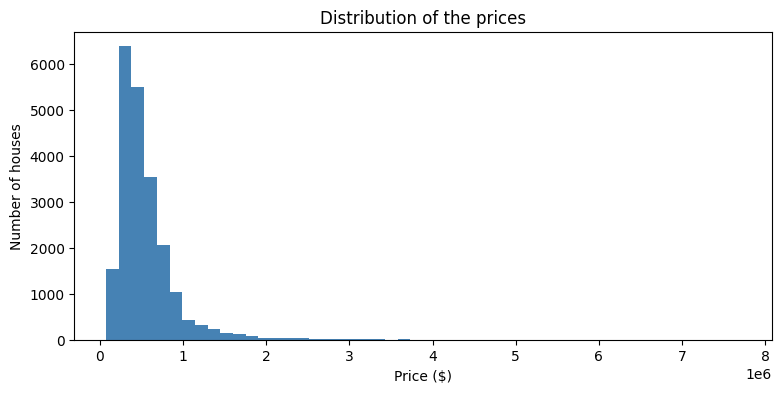

In [6]:
plt.figure(figsize=(9, 4))
plt.hist(df["price"], bins=50, color="steelblue")
plt.xlabel("Price ($)")
plt.ylabel("Number of houses")
plt.title("Distribution of the prices")
plt.show()

### How to read this plot

The shape is called **skewed to the right** : a big pile on the left, and a long thin tail going
right. Concretely :

+ most houses are between 200 000 and 700 000 $,
+ a handful go up to 7 700 000 $.

**Why it matters for the rest :** these few very expensive houses will produce enormous errors, and
they will weigh a lot in the score of the models. Keep it in mind when you read the results.

### YOUR TURN

Draw a **scatter plot** with `sqft_living` (the living surface) on the x axis and `price` on the
y axis. Use `s=2` and `alpha=0.3`, otherwise the 21 613 dots form a black blob.

Do not forget the labels and the title.

In [7]:
# TODO : complete the scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(...)
plt.xlabel(...)
plt.ylabel(...)
plt.title(...)
plt.show()

TypeError: scatter() missing 1 required positional argument: 'y'

<Figure size 800x500 with 0 Axes>

<details>
<summary><b>Hint</b></summary>

```python
plt.scatter(df["sqft_living"], df["price"], s=2, alpha=0.3)
```

**What you should see :** the dots go up from the bottom left to the top right. That means the
bigger the house, the more expensive it is. This is exactly the kind of relation a model can learn.

</details>

### EXAMPLE - correlations

The **correlation** is a number between -1 and +1 that measures how two columns move together :

+ **+1** : when one goes up, the other always goes up (perfect link)
+ **0** : no link at all
+ **-1** : when one goes up, the other goes down

Let us sort the columns by their correlation with the price.

In [8]:
correlations = df.corr(numeric_only=True)["price"].sort_values(ascending=False)
correlations

price            1.000000
sqft_living      0.702035
grade            0.667434
sqft_above       0.605567
sqft_living15    0.585379
bathrooms        0.525138
view             0.397293
sqft_basement    0.323816
bedrooms         0.308350
lat              0.307003
floors           0.256794
yr_renovated     0.126434
sqft_lot         0.089661
sqft_lot15       0.082447
yr_built         0.054012
long             0.021626
id              -0.016762
zipcode         -0.053203
Name: price, dtype: float64

### EXAMPLE - the correlation heatmap

Instead of reading numbers one by one, we can colour the whole table : red = positive correlation,
blue = negative, white = no link.

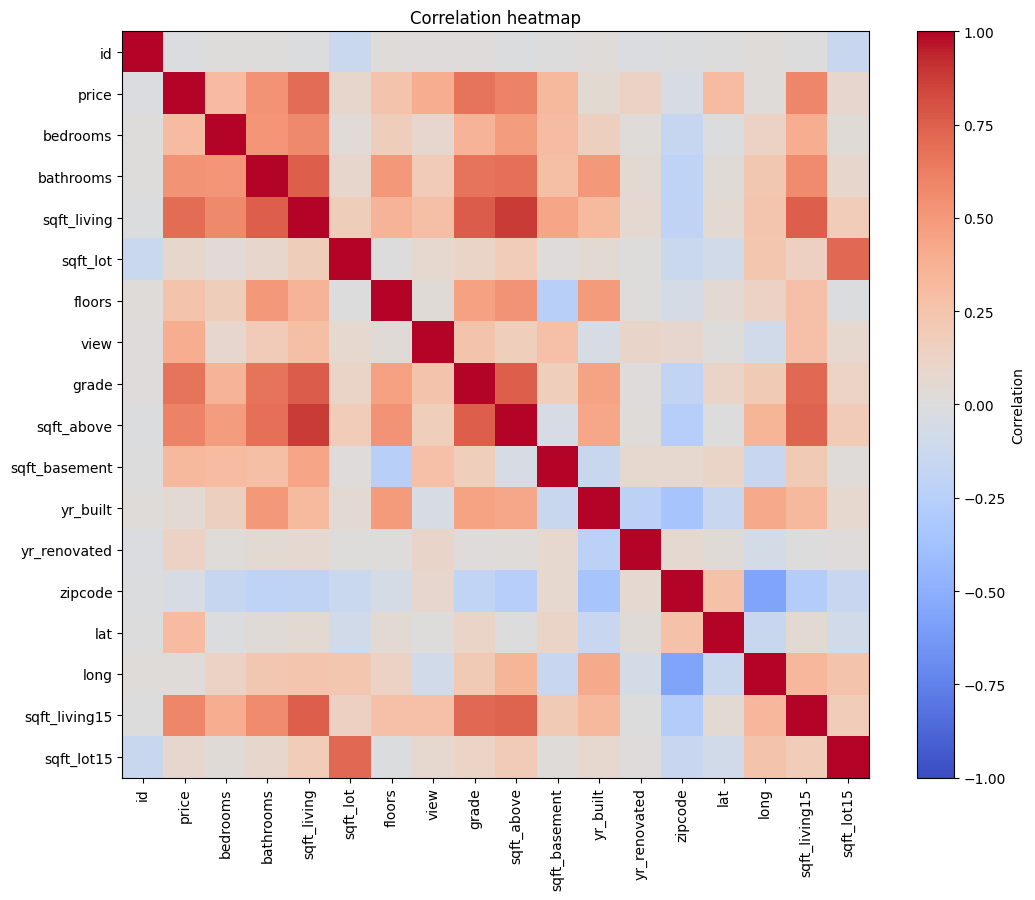

In [9]:
corr = df.corr(numeric_only=True)   # The full table of correlations

plt.figure(figsize=(11, 9))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)   # Draw the table as an image
plt.colorbar(label="Correlation")                    # The colour scale on the right

# Write the column names on the two axes
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)

plt.title("Correlation heatmap")
plt.tight_layout()   # Avoid the labels being cut off
plt.show()

### How to read the heatmap

**The diagonal is always dark red**, because every column is perfectly correlated with itself. It
carries no information, ignore it.

Then read it in two directions :

1. **The `price` row** : which columns are the most red ? Those are the ones that will help the model.
   You should find `sqft_living` (0.70), `grade` (0.67), `sqft_above` (0.61).

2. **The red squares that do NOT touch the price row.** For instance `sqft_living` and `sqft_above`
   are at 0.88 : they say almost the same thing (the surface above ground is most of the living
   surface). This is called **multicollinearity**, and it disturbs the linear models : they do not
   know which of the two deserves the credit.

Also notice `sqft_lot` (the land) is at 0.09 with the price : almost nothing. **The size of the
garden matters far less than the size of the house.** This is the kind of conclusion you are
expected to write in your report.

### YOUR TURN

Looking at the `correlations` list above, name the **3 columns most linked to the price**, and the
**2 columns that are useless** (correlation close to 0).

Write your answer in the text cell below (double-click on it to edit).

*Your answer :*

+ The 3 most useful columns are : ...
+ Two useless columns are : ...
+ In one sentence, what makes the price of a house here ? ...

---
# Step 2 - Clean the data

**A model only understands numbers.** Three problems to solve in this file :

| Problem | Column | Solution |
|---|---|---|
| Text instead of a number | `waterfront` (`"Y"` / `"N"`) | turn it into 1 / 0 |
| Text with an order | `condition` (`"Poor"` ... `"Very Good"`) | turn it into 1, 2, 3, 4, 5 |
| A date written as text | `date` (`"20141013T000000"`) | extract the year and the month |

Plus the columns to delete because they bring nothing.

### EXAMPLE - work on a copy

We never modify the original table. If you make a mistake, you would have to reload the file.

In [ ]:
data = df.copy()   # A copy we can safely destroy
print("Copy created")

### EXAMPLE - a column of text with 2 values

`waterfront` says whether the house is by the water. It contains `"Y"` or `"N"`.

The comparison `data["waterfront"] == "Y"` produces a column of `True`/`False`, and `.astype(int)`
turns `True` into 1 and `False` into 0.

In [ ]:
print("Before :", data["waterfront"].unique())

data["waterfront"] = (data["waterfront"] == "Y").astype(int)

print("After  :", data["waterfront"].unique())

### EXAMPLE - a column of text with an order

`condition` contains 5 values, and **their order has a meaning** : Poor is worse than Fair, which is
worse than Average...

We use a **dictionary** to say which number replaces which text. A dictionary associates keys with
values, written `{key: value}`. `.map()` applies it to the whole column.

In [ ]:
print("Before :", data["condition"].unique())

condition_order = {
    "Poor": 1,
    "Fair": 2,
    "Average": 3,
    "Good": 4,
    "Very Good": 5,
}
data["condition"] = data["condition"].map(condition_order)

print("After  :", sorted(data["condition"].unique()))
print("Missing values created :", data["condition"].isna().sum(), "(must be 0)")

**Why check that last line ?** If you had written `"Very good"` instead of `"Very Good"`, `.map()`
would not have found the key and would have silently produced `NaN`. Always check.

> **Going further :** here the order matters, so numbering 1 to 5 is correct. But for a column like
> a city name, there is no order (Paris is not "less than" Lyon). In that case you would use
> [get_dummies](https://pandas.pydata.org/docs/reference/api/pandas.get_dummies.html), which
> creates one column of 0/1 per city.

### EXAMPLE - the date

`"20141013T000000"` means 13 October 2014. As text it is useless. `pd.to_datetime` turns it into a
real date, and then `.dt.year` / `.dt.month` extract the pieces.

In [ ]:
data["date"] = pd.to_datetime(data["date"], format="%Y%m%dT%H%M%S")

data["year_sold"] = data["date"].dt.year
data["month_sold"] = data["date"].dt.month

data[["date", "year_sold", "month_sold"]].head()

### EXAMPLE - inventing a useful column

This is called **feature engineering** : building a new column that helps the model.

The year of construction alone is not very telling. The **age of the house at the moment of the
sale** is much more meaningful, and it is a simple subtraction.

In [ ]:
data["house_age"] = data["year_sold"] - data["yr_built"]

print(data["house_age"].describe())

**Look at the `min` : it is negative !**

A house cannot be sold before it is built. In reality these are houses sold *off-plan* : built in
2015, sold in 2014. There are 12 of them.

A negative age would confuse the model, so we bring them back to 0 with
[clip](https://pandas.pydata.org/docs/reference/api/pandas.Series.clip.html), which forces the
values to stay inside a range.

In [ ]:
print("Negative ages :", (data["house_age"] < 0).sum())

data["house_age"] = data["house_age"].clip(lower=0)   # Everything below 0 becomes 0

print("Negative ages after the fix :", (data["house_age"] < 0).sum())

### YOUR TURN

Create a column `is_renovated` that contains **1 if the house has been renovated, 0 otherwise**.

The information is in `yr_renovated` : it contains the year of the renovation, or `0` if the house
has never been renovated.

In [ ]:
# TODO : create the column is_renovated
data["is_renovated"] = ...

print(data["is_renovated"].value_counts())

<details>
<summary><b>Hint</b></summary>

Exactly the same idea as `waterfront` : a comparison gives True/False, `.astype(int)` gives 1/0.

```python
data["is_renovated"] = (data["yr_renovated"] > 0).astype(int)
```

You should find about 20 700 houses at 0 and 900 at 1.

</details>

### EXAMPLE - delete the useless columns

Three columns to remove, for three different reasons :

+ `id` : an arbitrary serial number. Knowing that a house is number 7129300520 tells you nothing
  about its price.
+ `date` : we already extracted everything we needed from it (`year_sold`, `month_sold`, `house_age`).
+ `zipcode` : this one is a trap. It looks like a number, but 98178 is not "bigger" than 98028, it is
  just a different area. And we already have `lat` and `long` which give the position properly.

In [ ]:
data = data.drop(columns=["id", "date", "zipcode"])

print("Remaining columns :")
print(list(data.columns))

### EXAMPLE - final check

Before going further, we verify that everything is numeric and that no `NaN` appeared.

In [ ]:
print("Size :", data.shape)
print("Missing values :", data.isna().sum().sum())
print()
print(data.dtypes)

If you see `object` in the types above, one text column escaped you : go back up.
Only `int64` and `float64` should remain.

---
# Step 3 - Split into training and testing

## Why is this the most important step of the notebook

Imagine a student who learns the answers of last year's exam **by heart**. On those exact questions
he gets 20/20. On new questions, he collapses. He did not understand, he memorised.

A model can do exactly the same. If we measure its score on the houses it was trained on, we measure
its memory, not its intelligence.

So we **hide 20% of the houses**. The model never sees them during the training. They are the real
exam.

| | |
|---|---|
| `X` | the **questions** : surface, rooms, year... everything except the price |
| `y` | the **answers** : the price |
| `_train` | 80% of the houses, to learn |
| `_test` | 20% of the houses, kept hidden, to grade |

In [ ]:
X = data.drop(columns=["price"])   # Everything EXCEPT the price
y = data["price"]                  # ONLY the price

print("X :", X.shape, "-> ", X.shape[1], "columns of information")
print("y :", y.shape)

`train_test_split` shuffles the houses then cuts them in two.

`random_state=42` fixes the randomness : you and your neighbour will get exactly the same split, and
so the same results. Without it, the numbers would change at every run.

[Documentation of train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,      # 20% for the test
    random_state=42,    # so that the result is reproducible
)

print("Training :", X_train.shape[0], "houses")
print("Testing  :", X_test.shape[0], "houses")

---
# Step 4 - Normalize the numbers

## The problem

Look at these two columns :

| Column | Minimum | Maximum |
|---|---|---|
| `bathrooms` | 0 | 8 |
| `sqft_lot` | 520 | 1 651 359 |

A model that compares houses by computing distances will find that a difference of 3 bathrooms
(a huge difference for a buyer) is negligible next to a difference of 10 000 sqft of land.
**The big numbers crush the small ones**, for no good reason.

## The solution : standardisation

For each column we apply :

$$ \text{new value} = \frac{\text{value} - \text{mean}}{\text{standard deviation}} $$

After that, every column has a mean of 0 and a standard deviation of 1. They are comparable.

## The trap to avoid

**The mean and the standard deviation must be computed on the training set ONLY.**

If you compute them on the whole table, information about the test houses (their mean) slips into the
training. The model gets a hint about the exam. Its score becomes falsely good. This is called
**data leakage**, and it is the most common mistake for beginners.

So : we compute the mean on `X_train`, and we reuse **that same mean** on `X_test`.

In [ ]:
# The mean and the standard deviation of each column, on the TRAINING set only
mean = X_train.mean()
std = X_train.std()

# The same two numbers are applied to the two sets
X_train_scaled = (X_train - mean) / std
X_test_scaled = (X_test - mean) / std

X_train_scaled.head()

### Check that it worked

In [ ]:
print("TRAINING set after normalization")
print("  mean (should be ~0) :", round(X_train_scaled.mean().mean(), 6))
print("  std  (should be ~1) :", round(X_train_scaled.std().mean(), 6))

print()
print("TEST set after normalization")
print("  mean (NOT exactly 0) :", round(X_test_scaled.mean().mean(), 6))

**Why is the test set not exactly at 0 ?**

Because we normalized it with the mean of the *training* set, not with its own. It is slightly off,
and that is precisely what we want : it is the proof that we did not cheat.

If you had found exactly 0 here, it would mean you leaked.

### YOUR TURN

Draw a histogram of `sqft_lot` **before** and **after** normalization, side by side, to see the
change of scale.

The code for two plots side by side is given, you only have to fill the two `plt.hist(...)`.

In [ ]:
plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)          # 1 row, 2 columns, this is plot number 1
# TODO : histogram of X_train["sqft_lot"], bins=50
plt.hist(...)
plt.title("Before normalization")
plt.xlabel("sqft_lot")

plt.subplot(1, 2, 2)          # this is plot number 2
# TODO : histogram of X_train_scaled["sqft_lot"], bins=50
plt.hist(...)
plt.title("After normalization")
plt.xlabel("sqft_lot (normalized)")

plt.tight_layout()
plt.show()

<details>
<summary><b>Hint</b></summary>

```python
plt.hist(X_train["sqft_lot"], bins=50)
plt.hist(X_train_scaled["sqft_lot"], bins=50)
```

**What to observe :** the *shape* of the two histograms is identical. Only the numbers on the
x axis change (from hundreds of thousands to a range around 0). Normalizing does not deform the
data, it only changes the unit.

</details>

---
# Step 5 - Train the models

## How a model works in scikit-learn

Always the same 3 lines, whatever the model :

```python
model = LinearRegression()          # 1. create it
model.fit(X_train_scaled, y_train)  # 2. train it : "here are the questions and the answers"
predictions = model.predict(X_test_scaled)   # 3. ask it the hidden questions
```

That is all. What changes from one model to another is only the first line.

## How to grade a model

We compare `predictions` with `y_test` (the true prices) using 3 numbers :

| Metric | What it measures | Good value |
|---|---|---|
| **MAE** | average error, **in dollars**. "On average I am wrong by 100 000 $" | as low as possible |
| **RMSE** | also in dollars, but **big mistakes count much more** | as low as possible |
| **R²** | percentage of the price variation explained. 1 = perfect, 0 = as bad as always answering the mean | as close to 1 as possible |

**Why MAE and RMSE both ?** Because comparing them is informative.
If RMSE is *much* bigger than MAE, it means the model is usually fine but makes a few catastrophic
mistakes (probably on the very expensive houses seen in step 1).

[Documentation of the metrics](https://scikit-learn.org/stable/modules/model_evaluation.html)

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []   # We will store the score of each model here

---
## Model 1 : Linear Regression

The simplest one. It looks for a formula of the form :

```
price = a * surface + b * bedrooms + c * grade + ... + constant
```

and it finds the best possible values for `a`, `b`, `c`...

It is our **baseline** : every other model has to beat it, otherwise it is not worth its complexity.

[Documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)

In [ ]:
from sklearn.linear_model import LinearRegression

model_linear = LinearRegression()              # 1. create
model_linear.fit(X_train_scaled, y_train)      # 2. train
pred_linear = model_linear.predict(X_test_scaled)   # 3. predict

# Grade it
mae = mean_absolute_error(y_test, pred_linear)
rmse = np.sqrt(mean_squared_error(y_test, pred_linear))
r2 = r2_score(y_test, pred_linear)

print("LINEAR REGRESSION")
print("  MAE  :", round(mae), "$")
print("  RMSE :", round(rmse), "$")
print("  R2   :", round(r2, 3))

results.append({"model": "Linear", "MAE": mae, "RMSE": rmse, "R2": r2})

### Look at the predictions

The most useful plot of the whole notebook. Each dot is one house :
the true price on the x axis, the predicted price on the y axis.

**If the model were perfect, every dot would be exactly on the red line.**

In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred_linear, s=4, alpha=0.25)

# The red line = perfect prediction
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         "r--", label="perfect prediction")

plt.xlabel("True price ($)")
plt.ylabel("Predicted price ($)")
plt.title("Linear Regression")
plt.legend()
plt.show()

### How to read this plot

Three things to look for, every time :

1. **Is the cloud following the line ?** If yes, the model works globally.
2. **Is it spreading out on the right ?** Here yes : the cheap houses are well predicted, the
   expensive ones much less. Normal, there are far fewer of them to learn from.
3. **Are the dots on the right *below* the line ?** That means the model **underestimates** the
   expensive houses. It does not dare to predict 5 million, so it stays cautious.

A linear model can also predict a **negative price**, which makes no sense for a house.
Check it in the next cell.

In [ ]:
print("Lowest prediction :", round(pred_linear.min()), "$")
print("Number of negative predictions :", (pred_linear < 0).sum())

---
## Model 2 : Decision Tree

A completely different approach. The tree asks a series of yes/no questions :

```
Is the surface > 2000 sqft ?
├── yes -> Is the grade > 8 ?
│          ├── yes -> price = 900 000 $
│          └── no  -> price = 600 000 $
└── no  -> Is the house older than 50 years ?
           └── ...
```

[Documentation](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html)

In [ ]:
from sklearn.tree import DecisionTreeRegressor

model_tree = DecisionTreeRegressor(random_state=42)
model_tree.fit(X_train_scaled, y_train)
pred_tree = model_tree.predict(X_test_scaled)

mae = mean_absolute_error(y_test, pred_tree)
rmse = np.sqrt(mean_squared_error(y_test, pred_tree))
r2 = r2_score(y_test, pred_tree)

print("DECISION TREE")
print("  MAE  :", round(mae), "$")
print("  RMSE :", round(rmse), "$")
print("  R2   :", round(r2, 3))

results.append({"model": "Decision Tree", "MAE": mae, "RMSE": rmse, "R2": r2})

### The student who learns by heart

Remember the introduction of step 3. Let us compare the score of the tree **on the houses it learned
on** and **on the hidden houses**.

In [ ]:
print("R2 on the TRAINING houses :", round(model_tree.score(X_train_scaled, y_train), 3))
print("R2 on the HIDDEN houses   :", round(model_tree.score(X_test_scaled, y_test), 3))

### How to read this

The first number is close to **1.000**, almost perfect. The second is far lower.

This gap is called **overfitting**. Left free, the tree grew until it had one branch per house of
the training set. It memorised them. Faced with a new house, it is lost.

**This is why we hid 20% of the data.** With only the first number, you would have believed you had
built a perfect model.

---
## Model 3 : Random Forest

The idea that fixes the previous problem : instead of one tree that memorises everything, we grow
**200 different trees**, each one on a random part of the data, and we take the **average** of their
answers.

Each tree makes mistakes, but they do not make the *same* mistakes, so the average is much more
reliable. It is a vote.

`n_estimators=200` is the number of trees. `n_jobs=-1` uses all the cores of your processor.

**This cell takes around 20 seconds to run, it is normal.**

[Documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html)

In [ ]:
from sklearn.ensemble import RandomForestRegressor

model_forest = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
model_forest.fit(X_train_scaled, y_train)
pred_forest = model_forest.predict(X_test_scaled)

mae = mean_absolute_error(y_test, pred_forest)
rmse = np.sqrt(mean_squared_error(y_test, pred_forest))
r2 = r2_score(y_test, pred_forest)

print("RANDOM FOREST")
print("  MAE  :", round(mae), "$")
print("  RMSE :", round(rmse), "$")
print("  R2   :", round(r2, 3))

results.append({"model": "Random Forest", "MAE": mae, "RMSE": rmse, "R2": r2})

---
## Model 4 : K-Nearest Neighbors

### YOUR TURN

This model is the most intuitive of all : to estimate the price of a house, it looks for the **10
most similar houses** in the training set and takes the average of their prices. Exactly what a real
estate agent does.

**This is the model that needs the normalization of step 4.** Without it, "similar" would only mean
"same land area", because that column has the biggest numbers.

Write the code yourself, copying the structure of the 3 previous models.

[Documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html)

In [ ]:
from sklearn.neighbors import KNeighborsRegressor

# TODO : create the model with n_neighbors=10
model_knn = ...

# TODO : train it on X_train_scaled and y_train


# TODO : predict on X_test_scaled
pred_knn = ...


# Grading (already written, do not change)
mae = mean_absolute_error(y_test, pred_knn)
rmse = np.sqrt(mean_squared_error(y_test, pred_knn))
r2 = r2_score(y_test, pred_knn)

print("K-NEAREST NEIGHBORS")
print("  MAE  :", round(mae), "$")
print("  RMSE :", round(rmse), "$")
print("  R2   :", round(r2, 3))

results.append({"model": "KNN (k=10)", "MAE": mae, "RMSE": rmse, "R2": r2})

<details>
<summary><b>Hint</b></summary>

```python
model_knn = KNeighborsRegressor(n_neighbors=10)
model_knn.fit(X_train_scaled, y_train)
pred_knn = model_knn.predict(X_test_scaled)
```

**Bonus experiment :** re-run this cell using `X_train` and `X_test` (the NON normalized versions)
instead of `X_train_scaled` and `X_test_scaled`. The R² collapses. That is the concrete proof that
step 4 was useful.

</details>

---
# Step 6 - Compare and analyse

All the scores were stored in `results`. We turn that list into a table, sorted by RMSE
(the lower, the better).

In [ ]:
scores = pd.DataFrame(results)
scores = scores.sort_values("RMSE").reset_index(drop=True)
scores

### The same thing as a plot

A table of 4 rows is readable, but in a report a plot is always more convincing.

In [ ]:
plt.figure(figsize=(8, 4))
plt.barh(scores["model"], scores["RMSE"], color="steelblue")
plt.gca().invert_yaxis()        # Put the best model on top
plt.xlabel("RMSE ($) - lower is better")
plt.title("Comparison of the models")
plt.tight_layout()
plt.show()

### What the model looks at

A Random Forest can tell you **which columns it actually used** to decide. Very useful to check
that it learned something sensible and not a coincidence.

In [ ]:
importances = pd.Series(model_forest.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=False)

plt.figure(figsize=(8, 5))
plt.barh(importances.head(10).index[::-1], importances.head(10).values[::-1], color="darkseagreen")
plt.xlabel("Importance")
plt.title("The 10 columns the forest uses the most")
plt.tight_layout()
plt.show()

### How to read the importances

Compare this plot with the correlations of step 1. You should find roughly the same columns at the
top (`sqft_living`, `grade`, `lat`...).

**If a strange column came out first** — for example `month_sold` — it would be a warning signal :
the model would have found a coincidence in the data rather than a real rule.

Notice `lat` (the latitude) is usually very high. The model rediscovered on its own that
**the neighbourhood makes the price**.

---
## Is one house well predicted ?

Let us take one specific house of the test set and look at what each model answered.

In [ ]:
i = 0   # Try other numbers : 1, 2, 10, 100...

print("House number", i)
print("  Living surface :", X_test.iloc[i]["sqft_living"], "sqft")
print("  Bedrooms       :", X_test.iloc[i]["bedrooms"])
print("  Grade          :", X_test.iloc[i]["grade"])
print()
print("  TRUE PRICE     :", round(y_test.iloc[i]), "$")
print()
print("  Linear         :", round(pred_linear[i]), "$")
print("  Decision Tree  :", round(pred_tree[i]), "$")
print("  Random Forest  :", round(pred_forest[i]), "$")
print("  KNN            :", round(pred_knn[i]), "$")

### YOUR TURN

Change `i` and run the cell again a few times. Try to find :

+ a house where all the models agree and are close to the truth,
+ a house where they are all badly wrong.

What do the badly predicted houses have in common ? (look at their price)

---
# Conclusion - what you have to write

Answer these questions in the text cell below. **This is the part that is graded**, the code is
only the tool.

### 1. Which model wins ?
Give its name and its 3 scores. By how much does it beat the linear regression (in dollars of MAE) ?

### 2. Is the error acceptable ?
Compare the MAE of the best model with the **average price** of a house (found in step 1).
An error of 70 000 $ on a house worth 100 000 $ is a disaster ; on a house worth 5 million it is
excellent. Give the error as a percentage.

### 3. Why is the Random Forest better than the single Decision Tree ?
Use the two numbers from the overfitting cell.

### 4. What did the model understand about the real estate market ?
Use the importance plot and the correlation heatmap. Name the 3 factors that make a price, and say
whether it matches your intuition.

### 5. Where does the model fail ?
Use the predicted-versus-true plot. Which houses are badly predicted, and why do you think so ?

*Your answers :*

**1.** ...

**2.** ...

**3.** ...

**4.** ...

**5.** ...

---
# To go further (optional)

Four ideas, from the easiest to the hardest :

1. **Change a setting.** Try `n_neighbors=3` then `50` for the KNN, or
   `max_depth=10` for the decision tree. Does it improve ? `max_depth` limits the growth of the
   tree and is precisely the cure against the overfitting seen earlier.

2. **Add a column.** For instance the ratio `sqft_living / sqft_lot` (how much of the land is
   built on). Does it enter the top 10 importances ?

3. **Predict the logarithm of the price.** Step 1 showed that the prices are skewed to the right.
   Training on `np.log(y_train)` fixes that. Careful, to get dollars back you have to apply
   `np.exp()` on the predictions before computing the metrics.

4. **Use the zipcode.** We deleted it because it is a fake number. The proper way to use it is
   `pd.get_dummies(data["zipcode"])`, which creates one 0/1 column per area. It often gains a few
   points of R².